# Human Activity Recognition Data Preparation

This notebook is the only stage that reads raw sensor CSV files. It validates the four activity folders, audits accelerometer and gyroscope streams, aligns readings by elapsed time, assigns recording-level splits, extracts window features, and writes reusable processed tables for the HMM notebook. Raw CSVs are read-only and never changed.

Run this notebook first from the repository root or from `notebooks/`. Then run `02_hmm_activity_recognition.ipynb`.

In [2]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import periodogram
from sklearn.preprocessing import StandardScaler

ACTIVITIES=["Still","Standing","Walking","Jumping"]
WINDOW_SECONDS=1.0
HOP_SECONDS=0.5
LARGE_GAP_FACTOR=1.5
PAIRED_RATE_TOLERANCE=0.02


def find_repo_root():
    for candidate in [Path.cwd(),*Path.cwd().parents]:
        if (candidate/"data"/"raw").is_dir() and (candidate/"data"/"sequences").is_dir() and (candidate/"notebooks").is_dir(): return candidate
    raise FileNotFoundError("Open this notebook from this repository or its notebooks folder.")
REPO_ROOT=find_repo_root()
RAW_ACTIVITY_DIR=REPO_ROOT/"data"/"raw"  # existing raw Sensor Logger folders
RAW_SEQUENCE_DIR=REPO_ROOT/"data"/"sequences"  # existing raw mixed-sequence files
PROCESSED_DIR=REPO_ROOT/"data"/"processed"
FIGURE_DIR=REPO_ROOT/"figures"
PROCESSED_DIR.mkdir(parents=True,exist_ok=True); FIGURE_DIR.mkdir(parents=True,exist_ok=True)
assert WINDOW_SECONDS==1.0 and HOP_SECONDS==0.5
print("Repository:",REPO_ROOT)
print("Raw activity data:",RAW_ACTIVITY_DIR)
print("Processed outputs:",PROCESSED_DIR)

Repository: C:\Users\hp\Documents\Codex\2026-10-30\i-x20\outputs\human_activity_hmm_github
Raw activity data: C:\Users\hp\Documents\Codex\2026-10-30\i-x20\outputs\human_activity_hmm_github\data\raw
Processed outputs: C:\Users\hp\Documents\Codex\2026-10-30\i-x20\outputs\human_activity_hmm_github\data\processed


## 1. Discover and validate the raw dataset

Each activity recording must have accelerometer, gyroscope, and metadata CSV files with a shared filename stem. Sensor columns are selected by name. Metadata fields `device name`, `recording time`, and `sampleRateMs` are required. Exactly 20 recordings are required in each of the four activity folders.

In [4]:
REQUIRED_SENSOR_COLUMNS={"seconds_elapsed","x","y","z"}
REQUIRED_METADATA_COLUMNS={"device name","recording time","sampleRateMs"}

def recording_sort_key(recording_id):
    m=re.search(r"(20\d{2}-\d{2}-\d{2}_\d{2}-\d{2}-\d{2})",recording_id)
    return m.group(1) if m else recording_id

def audit_stream(frame,path):
    missing_cols=REQUIRED_SENSOR_COLUMNS-set(frame.columns)
    if missing_cols: raise ValueError(f"{path}: missing sensor columns {sorted(missing_cols)}")
    t=pd.to_numeric(frame["seconds_elapsed"],errors="coerce").to_numpy(float)
    dt=np.diff(t); positive=dt[dt>0]; med_dt=float(np.median(positive)) if len(positive) else np.nan
    return {"rows":len(frame),"duration_s":float(np.nanmax(t)-np.nanmin(t)) if np.isfinite(t).any() else np.nan,
            "median_interval_s":med_dt,"min_interval_s":float(np.min(dt)) if len(dt) else np.nan,
            "max_interval_s":float(np.max(dt)) if len(dt) else np.nan,
            "median_rate_hz":1.0/med_dt if med_dt>0 else np.nan,
            "missing_values":int(frame.isna().sum().sum()),"duplicate_timestamps":int(np.sum(dt==0)),
            "non_monotonic_timestamps":int(np.sum(dt<0)),
            "large_gaps":int(np.sum(dt>LARGE_GAP_FACTOR*med_dt)) if med_dt>0 else 0}

def clean_stream(frame,path):
    missing_cols=REQUIRED_SENSOR_COLUMNS-set(frame.columns)
    if missing_cols: raise ValueError(f"{path}: missing required columns {sorted(missing_cols)}")
    before=len(frame); frame=frame.copy()
    for col in ["seconds_elapsed","x","y","z"]: frame[col]=pd.to_numeric(frame[col],errors="coerce")
    if frame[list(REQUIRED_SENSOR_COLUMNS)].isna().any().any(): raise ValueError(f"{path}: missing/non-numeric required values; reported, not imputed")
    if not np.isfinite(frame[list(REQUIRED_SENSOR_COLUMNS)].to_numpy(float)).all(): raise ValueError(f"{path}: non-finite timestamps or axes")
    if frame.seconds_elapsed.duplicated().any(): raise ValueError(f"{path}: duplicate timestamps; reported, not dropped")
    # Preserve the raw-order issue in the audit, then sort explicitly before time-based alignment.
    frame=frame.sort_values("seconds_elapsed",kind="stable").reset_index(drop=True)
    t=frame.seconds_elapsed.to_numpy(float); dt=np.diff(t)
    if len(t)<2 or np.any(dt<=0): raise ValueError(f"{path}: timestamps must be strictly increasing after sorting")
    med=np.median(dt)
    if np.any(dt>LARGE_GAP_FACTOR*med): raise ValueError(f"{path}: large timestamp gap exceeds {LARGE_GAP_FACTOR:g} x median")
    return frame,before-len(frame)

def record_features(acc,gyro,acc_path,gyro_path):
    a,removed_a=clean_stream(acc,acc_path); g,removed_g=clean_stream(gyro,gyro_path)
    fs_a=1/np.median(np.diff(a.seconds_elapsed)); fs_g=1/np.median(np.diff(g.seconds_elapsed))
    rate_difference=abs(fs_a-fs_g)/min(fs_a,fs_g)
    if rate_difference>PAIRED_RATE_TOLERANCE: raise ValueError(f"Paired stream rate difference {rate_difference:.2%} exceeds {PAIRED_RATE_TOLERANCE:.0%}")
    start=max(float(a.seconds_elapsed.min()),float(g.seconds_elapsed.min())); end=min(float(a.seconds_elapsed.max()),float(g.seconds_elapsed.max()))
    if end-start<WINDOW_SECONDS: raise ValueError("Accelerometer and gyroscope have less than one second of common time range")
    fs=min(fs_a,fs_g)
    # Both sensors are interpolated by elapsed time, never by row position.
    grid=np.arange(start,end+0.25/fs,1/fs); grid=grid[grid<=end+1e-9]
    aligned={}
    for name,frame in [("acc",a),("gyro",g)]:
        source_t=frame.seconds_elapsed.to_numpy(float); axes=frame[["x","y","z"]].to_numpy(float)
        aligned[name]=np.column_stack([np.interp(grid,source_t,axes[:,j]) for j in range(3)])
    nwin=int(round(WINDOW_SECONDS*fs)); nhop=int(round(HOP_SECONDS*fs)); rows=[]
    for i in range(0,len(grid)-nwin+1,nhop):
        row={"time_start_s":float(grid[i]-start),"time_end_s":float(grid[i+nwin-1]-start),
             "time_center_s":float((grid[i]+grid[i+nwin-1])/2-start),"sample_rate_hz":fs,
             "common_start_s":start,"common_end_s":end,"paired_rate_difference_pct":rate_difference*100,
             "removed_invalid_acc_rows":removed_a,"removed_invalid_gyro_rows":removed_g}
        for prefix,values in aligned.items():
            xyz=values[i:i+nwin]; mag=np.linalg.norm(xyz,axis=1)
            for j,axis in enumerate(["x","y","z"]):
                v=xyz[:,j]; row[f"{prefix}_{axis}_mean"]=v.mean(); row[f"{prefix}_{axis}_std"]=v.std(); row[f"{prefix}_{axis}_rms"]=np.sqrt(np.mean(v*v))
            row[f"{prefix}_mag_mean"]=mag.mean(); row[f"{prefix}_mag_std"]=mag.std(); row[f"{prefix}_mag_rms"]=np.sqrt(np.mean(mag*mag))
            freq,power=periodogram(mag-mag.mean(),fs=fs,detrend="constant",scaling="spectrum"); positive=freq>0
            row[f"{prefix}_dominant_hz"]=freq[positive][np.argmax(power[positive])] if positive.any() else 0.0
            row[f"{prefix}_spectral_energy"]=power[positive].sum()
            prob=power[positive]; prob=prob/prob.sum() if prob.sum()>0 else prob
            row[f"{prefix}_spectral_entropy"]=-(prob*np.log(prob+1e-12)).sum()
        rows.append(row)
    aligned_frame=pd.DataFrame({"time_from_common_start_s":grid-start,"sample_rate_hz":fs,
        **{f"acc_{axis}":aligned["acc"][:,j] for j,axis in enumerate(["x","y","z"])},
        **{f"gyro_{axis}":aligned["gyro"][:,j] for j,axis in enumerate(["x","y","z"])}})
    return pd.DataFrame(rows),{"acc_rate_hz":fs_a,"gyro_rate_hz":fs_g,"target_rate_hz":fs,
        "paired_rate_difference_pct":rate_difference*100,"common_start_s":start,"common_end_s":end,
        "common_duration_s":end-start,"removed_acc_rows":removed_a,"removed_gyro_rows":removed_g},aligned_frame

recordings=[]; aligned_recordings=[]; audit_rows=[]
for activity in ACTIVITIES:
    folder=RAW_ACTIVITY_DIR/activity
    if not folder.is_dir(): raise FileNotFoundError(f"Missing activity folder {folder}")
    acc_paths=sorted(folder.glob("*_accelerometer.csv"))
    if len(acc_paths)!=20: raise AssertionError(f"Expected 20 recordings in {activity}, found {len(acc_paths)}")
    total_duration=0.0
    for acc_path in acc_paths:
        rid=acc_path.name.removesuffix("_accelerometer.csv")
        gyro_path=folder/f"{rid}_gyroscope.csv"; meta_path=folder/f"{rid}_metadata.csv"
        missing_files=[str(p) for p in [acc_path,gyro_path,meta_path] if not p.is_file()]
        if missing_files: raise FileNotFoundError(f"{rid}: missing required paired file(s) {missing_files}")
        acc=pd.read_csv(acc_path); gyro=pd.read_csv(gyro_path); meta=pd.read_csv(meta_path)
        missing_meta=REQUIRED_METADATA_COLUMNS-set(meta.columns)
        if meta.empty or missing_meta: raise ValueError(f"{meta_path}: empty metadata or required columns missing: {sorted(missing_meta)}")
        aa=audit_stream(acc,acc_path); ga=audit_stream(gyro,gyro_path)
        features,pair,aligned_data=record_features(acc,gyro,acc_path,gyro_path)
        total_duration+=pair["common_duration_s"]
        audit_rows.append({"activity":activity,"recording_id":rid,"metadata_device":meta.iloc[0]["device name"],
            **{f"acc_{k}":v for k,v in aa.items()},**{f"gyro_{k}":v for k,v in ga.items()},**pair})
        features["recording_id"]=rid; features["activity"]=activity; features["source"]="single_activity"
        features["sequence_role"]="labeled_single_activity"; recordings.append(features)
        aligned_data["recording_id"]=rid; aligned_data["activity"]=activity; aligned_data["source"]="single_activity"; aligned_recordings.append(aligned_data)
    if total_duration<90: raise AssertionError(f"{activity} has {total_duration:.2f}s; at least 90s required")

audit=pd.DataFrame(audit_rows)
assert len(audit)==80 and audit.groupby("activity").recording_id.nunique().reindex(ACTIVITIES).eq(20).all()
display(audit.round(6))
print("Observed accelerometer median-rate range: {:.3f}-{:.3f} Hz".format(audit.acc_median_rate_hz.min(),audit.acc_median_rate_hz.max()))
print("Observed gyroscope median-rate range: {:.3f}-{:.3f} Hz".format(audit.gyro_median_rate_hz.min(),audit.gyro_median_rate_hz.max()))
print("Per-activity totals:")
display(audit.groupby("activity").agg(recordings=("recording_id","nunique"),total_seconds=("common_duration_s","sum"),min_seconds=("common_duration_s","min"),max_seconds=("common_duration_s","max"),median_rate_hz=("acc_median_rate_hz","median")).reindex(ACTIVITIES).round(3))

Observed accelerometer median-rate range: 99.988-100.020 Hz
Observed gyroscope median-rate range: 99.988-100.020 Hz
Per-activity totals:


,activity,recording_id,metadata_device,acc_rows,acc_duration_s,acc_median_interval_s,acc_min_interval_s,acc_max_interval_s,acc_median_rate_hz,acc_missing_values,acc_duplicate_timestamps,acc_non_monotonic_timestamps,acc_large_gaps,gyro_rows,gyro_duration_s,gyro_median_interval_s,gyro_min_interval_s,gyro_max_interval_s,gyro_median_rate_hz,gyro_missing_values,gyro_duplicate_timestamps,gyro_non_monotonic_timestamps,gyro_large_gaps,acc_rate_hz,gyro_rate_hz,target_rate_hz,paired_rate_difference_pct,common_start_s,common_end_s,common_duration_s,removed_acc_rows,removed_gyro_rows
0,Still,Still_01_2026-10-28_09-00-58,iPhone XR,840,8.388501,0.009998,0.009995,0.010002,100.019535,0,0,0,0,840,8.388501,0.009998,0.009995,0.010002,100.019535,0,0,0,0,100.019535,100.019535,100.019535,0.0,0.123258,8.511759,8.388501,0,0
1,Still,Still_02_2026-10-28_09-01-27,iPhone XR,665,6.638899,0.009998,0.009994,0.010001,100.019535,0,0,0,0,665,6.638899,0.009998,0.009994,0.010001,100.019535,0,0,0,0,100.019535,100.019535,100.019535,0.0,0.090969,6.729869,6.638899,0,0
2,Still,Still_03_2026-10-28_09-02-18,iPhone XR,772,7.708781,0.009998,0.009994,0.010002,100.019535,0,0,0,0,772,7.708781,0.009998,0.009994,0.010002,100.019535,0,0,0,0,100.019535,100.019535,100.019535,0.0,0.104334,7.813115,7.708781,0,0
3,Still,Still_04_2026-10-28_09-03-39,iPhone XR,727,7.258827,0.009998,0.009996,0.010003,100.019535,0,0,0,0,727,7.258827,0.009998,0.009996,0.010003,100.019535,0,0,0,0,100.019535,100.019535,100.019535,0.0,0.106339,7.365166,7.258827,0,0
4,Still,Still_05_2026-10-28_09-04-13,iPhone XR,763,7.618752,0.009998,0.009996,0.010002,100.019535,0,0,0,0,763,7.618752,0.009998,0.009996,0.010002,100.019535,0,0,0,0,100.019535,100.019535,100.019535,0.0,0.089737,7.708488,7.618752,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,Jumping,Jumping_16_2026-10-29_17-48-09,iPhone XR,821,8.199522,0.009999,0.009993,0.010005,100.007325,0,0,0,0,821,8.199522,0.009999,0.009993,0.010005,100.007325,0,0,0,0,100.007325,100.007325,100.007325,0.0,0.108511,8.308033,8.199522,0,0
76,Jumping,Jumping_17_2026-10-29_17-48-21,iPhone XR,767,7.659551,0.009999,0.009994,0.010004,100.007325,0,0,0,0,767,7.659551,0.009999,0.009994,0.010004,100.007325,0,0,0,0,100.007325,100.007325,100.007325,0.0,0.106881,7.766431,7.659551,0,0
77,Jumping,Jumping_18_2026-10-29_17-48-35,iPhone XR,805,8.039521,0.009999,0.009996,0.010004,100.007325,0,0,0,0,805,8.039521,0.009999,0.009996,0.010004,100.007325,0,0,0,0,100.007325,100.007325,100.007325,0.0,0.119176,8.158697,8.039521,0,0
78,Jumping,Jumping_19_2026-10-29_17-48-52,iPhone XR,930,9.289383,0.009999,0.009994,0.010006,100.009767,0,0,0,0,930,9.289383,0.009999,0.009994,0.010006,100.009767,0,0,0,0,100.009767,100.009767,100.009767,0.0,0.112318,9.401701,9.289383,0,0


,recordings,total_seconds,min_seconds,max_seconds,median_rate_hz
activity,,,,,
Still,20,152.259,6.639,8.489,100.010
Standing,20,145.605,5.400,8.279,100.010
Walking,20,165.012,7.489,9.499,100.010
Jumping,20,157.804,6.680,9.289,100.005


## 2. Audit and cleaning decisions

The audit records raw row counts, durations, timestamp interval minima/maxima/medians, effective median rates, missing values across every CSV column, duplicate and non-monotonic timestamps, and gaps greater than 1.5 times the median interval. It also records paired rate differences and common timestamp coverage.

Rows are ordered by elapsed time before alignment. Missing/non-numeric required values, duplicates, non-finite values, material gaps, missing files/columns, or paired rates differing by more than 2% stop processing with a clear error. Invalid values are reported, not imputed; no rows are silently discarded. The supplied recordings have no such invalid rows or gaps, so there are zero removed rows. This keeps the cleaning decision reproducible and avoids inventing sensor values.

## 3. Windowing and features

For each paired recording, readings are interpolated on elapsed time over the streams' common overlap at the lower measured rate. At the observed rate near 100 Hz, a 1.0-second window has about 100 samples and about 1 Hz periodogram resolution; a 0.5-second hop advances about 50 samples and creates 50% overlap. The window captures brief movement patterns while the hop gives a smoother timeline. Rates are derived from timestamps and supplied to the periodogram, not hard-coded.

The 30 features keep accelerometer (`acc_`) and gyroscope (`gyro_`) signals distinct. Per-axis means, standard deviations and RMS describe posture and movement intensity. Magnitude statistics reduce phone-orientation sensitivity. Dominant frequency captures cadence; spectral energy and entropy help distinguish concentrated periodic from irregular motion. Mixed-sequence windows are retained only when the full 1-second window falls inside an estimated stable activity interval, so no window crosses an unlabeled transition.

In [7]:
# Reserve the two chronologically newest complete recordings per activity for final testing.
split_rows=[]; split_lookup={}
for activity in ACTIVITIES:
    ids=sorted(audit.loc[audit.activity==activity,"recording_id"].tolist(),key=recording_sort_key)
    if len(ids)!=20: raise AssertionError(f"{activity}: expected 20 recording IDs")
    test_ids=set(ids[-2:])
    for rid in ids: split_lookup[("single_activity",rid)]="test" if rid in test_ids else "train"
    split_rows += [{"activity":activity,"source":"single_activity","recording_id":rid,"partition":split_lookup[("single_activity",rid)]} for rid in ids]

ESTIMATED_INTERVALS={
 "All_01_2026-10-30_19-48-49":[(0,11,"Still"),(16,21,"Standing"),(21,32,"Walking"),(33,42.5,"Jumping")],
 "All_02_2026-10-30_19-50-02":[(0,10,"Still"),(15,21,"Standing"),(21,32,"Walking"),(33,41.1,"Jumping")],
 "All_03_2026-10-30_19-51-14":[(0,11,"Still"),(14,21,"Standing"),(21,32,"Walking"),(33,41.1,"Jumping")],
}
for rid,intervals in ESTIMATED_INTERVALS.items():
    split_lookup[("estimated_mixed_sequence",rid)]="qualitative_only" if rid.endswith("19-51-14") else "train"
    split_rows.append({"activity":"mixed_sequence","source":"estimated_mixed_sequence","recording_id":rid,"partition":split_lookup[("estimated_mixed_sequence",rid)]})
    ap=RAW_SEQUENCE_DIR/f"{rid}_accelerometer.csv"; gp=RAW_SEQUENCE_DIR/f"{rid}_gyroscope.csv"
    if not ap.is_file() or not gp.is_file(): raise FileNotFoundError(f"{rid}: both raw sensor streams are required")
    acc=pd.read_csv(ap); gyro=pd.read_csv(gp)
    fa=audit_stream(acc,ap); fg=audit_stream(gyro,gp)
    features,pair,aligned_data=record_features(acc,gyro,ap,gp)
    features["activity"]=pd.Series([None]*len(features),dtype="object")
    for start,end,label in intervals:
        # Keep only complete windows fully inside an estimated stable interval.
        mask=(features.time_start_s>=start)&(features.time_end_s<=end)
        features.loc[mask,"activity"]=label
    features["recording_id"]=rid; features["source"]="estimated_mixed_sequence"
    features["sequence_role"]="transition_training_estimate" if split_lookup[("estimated_mixed_sequence",rid)]=="train" else "qualitative_estimate"
    recordings.append(features)
    aligned_data["activity"]=pd.Series([None]*len(aligned_data),dtype="object")
    for start,end,label in intervals:
        aligned_data.loc[aligned_data.time_from_common_start_s.between(start,end,inclusive="both"),"activity"]=label
    aligned_data["recording_id"]=rid; aligned_data["source"]="estimated_mixed_sequence"
    aligned_data["sequence_role"]=features.sequence_role.iloc[0]; aligned_recordings.append(aligned_data)
    audit_rows.append({"activity":"mixed_sequence","recording_id":rid,"metadata_device":"not provided",
       **{f"acc_{k}":v for k,v in fa.items()},**{f"gyro_{k}":v for k,v in fg.items()},**pair})

audit=pd.DataFrame(audit_rows)
all_windows=pd.concat(recordings,ignore_index=True)
all_windows["partition"]=[split_lookup[(src,rid)] for src,rid in zip(all_windows.source,all_windows.recording_id)]
cleaned_sensor_readings=pd.concat(aligned_recordings,ignore_index=True)
cleaned_sensor_readings["partition"]=[split_lookup[(src,rid)] for src,rid in zip(cleaned_sensor_readings.source,cleaned_sensor_readings.recording_id)]
split_metadata=pd.DataFrame(split_rows)
assert split_metadata.query("source=='single_activity' and partition=='test'").groupby("activity").recording_id.nunique().eq(2).all()
assert split_metadata.query("source=='single_activity' and partition=='test'").recording_id.nunique()==8
assert all_windows.loc[all_windows.partition=="test","recording_id"].nunique()==8
print("Window rows by source and partition:")
display(all_windows.groupby(["source","partition"],dropna=False).agg(windows=("recording_id","size"),recordings=("recording_id","nunique")))
print("Activity windows by class and partition:")
display(all_windows.groupby(["activity","partition"],dropna=False).size().rename("windows").to_frame())

FEATURE_COLUMNS=[c for c in all_windows.columns if c.startswith(("acc_","gyro_")) and c not in {"acc_rate_hz","gyro_rate_hz"}]
assert len(FEATURE_COLUMNS)==30, f"Expected 30 paired sensor features, got {len(FEATURE_COLUMNS)}"
train_mask=(all_windows.partition=="train") & all_windows.activity.notna()
scaler=StandardScaler().fit(all_windows.loc[train_mask,FEATURE_COLUMNS])
scaled=all_windows.copy(); scaled[FEATURE_COLUMNS]=scaler.transform(all_windows[FEATURE_COLUMNS])
scaler_parameters=pd.DataFrame({"feature":FEATURE_COLUMNS,"mean":scaler.mean_,"scale":scaler.scale_,"training_windows":int(train_mask.sum())})

# Store deterministic outputs consumed by notebook 02.
audit.to_csv(PROCESSED_DIR/"quality_audit.csv",index=False)
cleaned_sensor_readings.to_csv(PROCESSED_DIR/"cleaned_sensor_readings.csv",index=False)
split_metadata.to_csv(PROCESSED_DIR/"recording_split.csv",index=False)
all_windows.to_csv(PROCESSED_DIR/"window_features_raw.csv",index=False)
scaled.to_csv(PROCESSED_DIR/"window_features_scaled.csv",index=False)
scaler_parameters.to_csv(PROCESSED_DIR/"scaler_parameters.csv",index=False)
print("Saved cleaned aligned readings, audit, split, raw/scaled features and training-only scaler parameters to",PROCESSED_DIR)
print("Scaler fit windows:",int(train_mask.sum()),"| test recordings excluded:",split_metadata.query("partition=='test'").recording_id.nunique())

Window rows by source and partition:
Activity windows by class and partition:
Saved cleaned aligned readings, audit, split, raw/scaled features and training-only scaler parameters to C:\Users\hp\Documents\Codex\2026-10-30\i-x20\outputs\human_activity_hmm_github\data\processed
Scaler fit windows: 1135 | test recordings excluded: 8


windows  recordings
source                   partition                            
estimated_mixed_sequence qualitative_only       81           1
                         train                 165           2
single_activity          test                  119           8
                         train                1006          72

windows
activity partition                
Jumping  qualitative_only       14
         test                   32
         train                 287
Standing qualitative_only       12
         test                   27
         train                 252
Still    qualitative_only       21
         test                   29
         train                 285
Walking  qualitative_only       20
         test                   31
         train                 311
NaN      qualitative_only       14
         train                  36

## 4. Preprocessing review figures and exported artifacts

The sample plot shows both sensor sources from one labeled recording. The feature plots use training recordings only and show selected magnitude variability features; they are descriptive, not a basis for tuning on the final test set. `window_features_scaled.csv` contains the transformed windows and metadata; `scaler_parameters.csv` records the exact training-only means/scales. Notebook 02 consumes these outputs and does not read raw CSVs or fit another scaler.

Audit exceptions (all raw files): {'acc_missing_values': 0, 'acc_duplicate_timestamps': 0, 'acc_non_monotonic_timestamps': 0, 'acc_large_gaps': 0, 'gyro_missing_values': 0, 'gyro_duplicate_timestamps': 0, 'gyro_non_monotonic_timestamps': 0, 'gyro_large_gaps': 0}


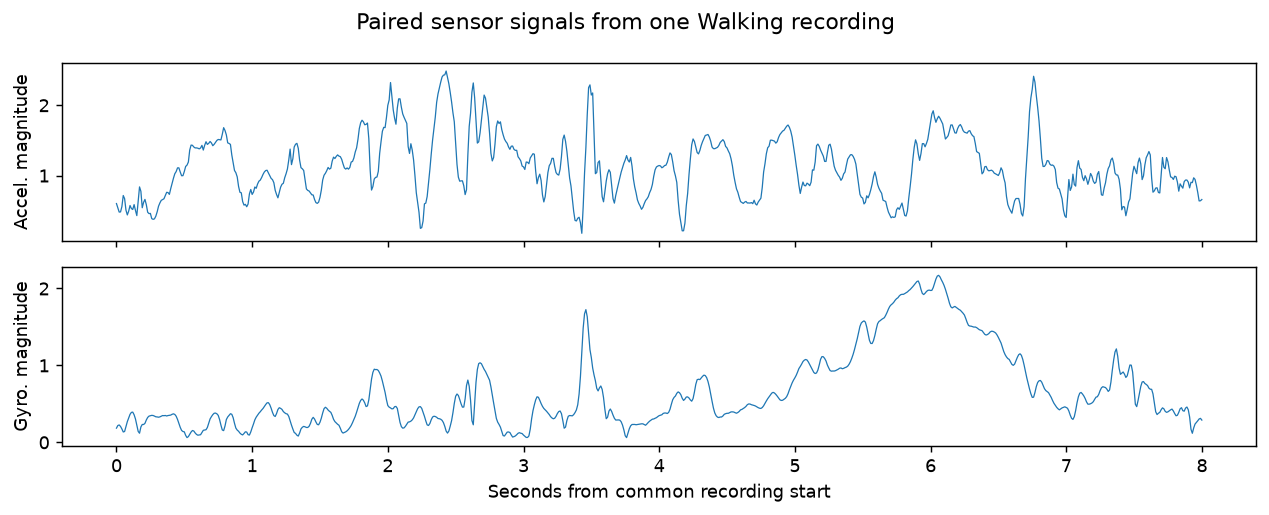

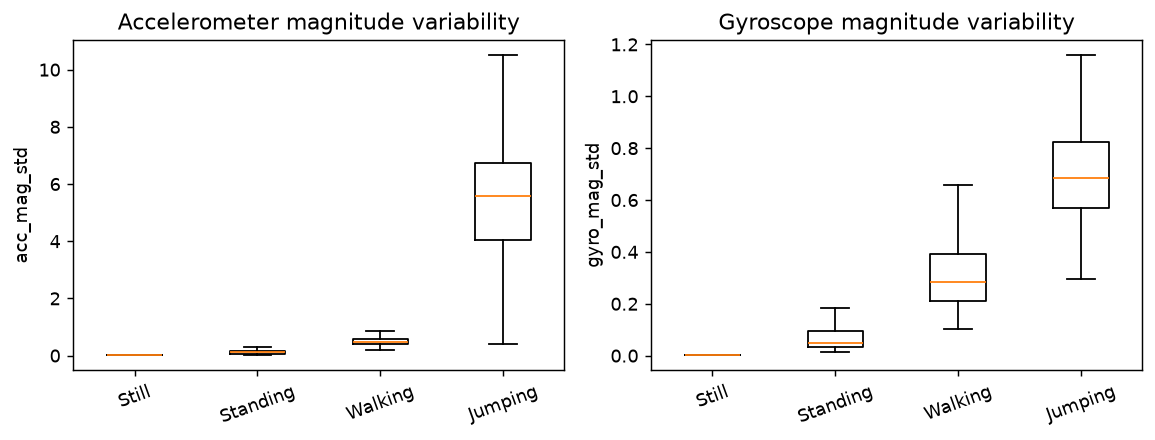

In [9]:
sample_id=sorted(audit.loc[audit.activity=="Walking","recording_id"])[0]
sample_path=RAW_ACTIVITY_DIR/"Walking"/f"{sample_id}_accelerometer.csv"
acc=pd.read_csv(sample_path); gyro=pd.read_csv(RAW_ACTIVITY_DIR/"Walking"/f"{sample_id}_gyroscope.csv")
acc,_=clean_stream(acc,sample_path); gyro,_=clean_stream(gyro,RAW_ACTIVITY_DIR/"Walking"/f"{sample_id}_gyroscope.csv")
left=max(acc.seconds_elapsed.min(),gyro.seconds_elapsed.min()); right=min(acc.seconds_elapsed.max(),gyro.seconds_elapsed.min()+8.0)
fig,axes=plt.subplots(2,1,figsize=(10,4),sharex=True)
for ax,name,frame in [(axes[0],"Accel. magnitude",acc),(axes[1],"Gyro. magnitude",gyro)]:
    part=frame[(frame.seconds_elapsed>=left)&(frame.seconds_elapsed<=right)]
    mag=np.linalg.norm(part[["x","y","z"]].to_numpy(float),axis=1)
    ax.plot(part.seconds_elapsed-left,mag,lw=.7); ax.set_ylabel(name)
axes[-1].set_xlabel("Seconds from common recording start"); fig.suptitle("Paired sensor signals from one Walking recording")
fig.tight_layout(); fig.savefig(FIGURE_DIR/"sample_sensor_signal.png",dpi=180); plt.show()

fig,axes=plt.subplots(1,2,figsize=(9,3.5))
train_single=all_windows[(all_windows.partition=="train")&(all_windows.source=="single_activity")]
for ax,feature,title in [(axes[0],"acc_mag_std","Accelerometer magnitude variability"),(axes[1],"gyro_mag_std","Gyroscope magnitude variability")]:
    values=[train_single.loc[train_single.activity==a,feature].dropna().to_numpy() for a in ACTIVITIES]
    ax.boxplot(values,tick_labels=ACTIVITIES,showfliers=False); ax.set_title(title); ax.set_ylabel(feature); ax.tick_params(axis="x",rotation=20)
fig.tight_layout(); fig.savefig(FIGURE_DIR/"feature_distributions.png",dpi=180); plt.show()
print("Audit exceptions (all raw files):",audit[[c for c in audit.columns if any(k in c for k in ["missing_values","duplicate_timestamps","non_monotonic_timestamps","large_gaps"]) ]].sum().to_dict())